**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_012_공식형_분류_중고차거래

### **중고차 거래 — <span style="color:darkgreen">빠른 판매 여부</span> 예측 모델 개발**
---

- 도메인 : 중고차 거래
- 목  표 : 차량이 한 달 안에 팔릴지 여부를 예측하는 인공지능모델 개발
- 가격팀은 차량 상태 정보로 적정 시세를 예측하는 모델을 도입하려 한다.
- 매물 가격 기준이 제각각이라 에이스휠는 객관적인 시세 산정 기준이 필요하다.
- 분석에는 약 1,890건 규모의 차량 데이터가 제공된다.
- 빠른 판매 여부를 미리 알 수 있다면 에이스휠의 운영 효율이 크게 개선될 것으로 보고 있다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 에이스휠의 데이터로 차량이 한 달 안에 팔릴지 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_excel, head, crosstab, quantile, drop, reset_index, dropna, sum, isnull, get_dummies, info, DataFrame, sort_values, columns, shape) · seaborn(jointplot, barplot) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, DecisionTreeClassifier, fit, RandomForestClassifier, feature_importances_, predict, f1_score, LabelEncoder) · TensorFlow(Keras)(Sequential, EarlyStopping, ModelCheckpoint, compile, fit, Dense, Dropout, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.95 / 5)
- 예상 소요 시간 : 약 124분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 중고차 거래 (유통·커머스)

**[ 데이터 컬럼 설명 (데이터 파일명: data.xlsx) ]**

- Quick_Sale            : 빠른 판매 여부 (Slow, Quick)
- Reg_No                : 등록번호
- Mileage_Km            : 주행거리(km)
- Engine_Cc             : 배기량(cc)
- Car_Age               : 연식(년)
- Accident_Cnt          : 사고 이력 횟수
- Owner_Cnt             : 소유자 변경 횟수
- Inspect_Score         : 성능점검 점수
- Option_Cnt            : 옵션 장착 수
- New_Price             : 신차 출고가(만원)
- Repair_Cost           : 누적 수리비(만원)
- Brand                 : 제조사
- Fuel                  : 연료
- Gearbox               : 변속기
- Color                 : 색상

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- import 할 모듈 : `pandas`
- 붙일 별칭 : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [3]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd


In [ ]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답01 = 'pd'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 2글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as p_

정답01 = 'p_'   # 빈칸에 넣은 단어
```

</details>

### **2. AI 모델링을 위해 분석할 데이터가 엑셀 파일로 제공되었습니다. pandas로 엑셀 파일을 읽어 데이터프레임 변수명 data 에 할당하고 첫 3개 행을 출력하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_excel, head) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 데이터프레임 변수명 : data
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 읽어 올 파일 : data.xlsx
    - 파일 형식은 엑셀(.xlsx) 입니다 (엑셀 읽기에는 openpyxl 이 필요하며 Colab 에는 설치되어 있습니다)
- **[결과 변수]** 결과는 반드시 `data` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(data.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 5점

---

In [4]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

data = pd.read_excel('aa23-m2-data.xlsx')
data.head(3)

print(data.shape)

(1888, 15)


In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(1888, 15)

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

엑셀 파일 형식에 맞는 pandas 읽기 함수를 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_excel`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `data` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import pandas as pd

data = pd.read_excel('./data.xlsx')
data.head(3)

# [data] 결과 확인 (LMS 에는 이 출력값을 입력)
print(data.shape)
```

</details>

### **3. 연료(Fuel)와(과) 빠른 판매 여부(Quick_Sale)의 관계를 교차표로 확인하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(crosstab) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 2번 `data`
- `pd.crosstab` 으로 연료(Fuel)과 빠른 판매 여부(Quick_Sale)의 교차표를 만들어 변수 `ct` 에 저장하세요
    - 대상 데이터프레임 : data
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 코드 셀 맨 아래에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [5]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

ct = pd.crosstab(data['Fuel'], data['Quick_Sale'])
ct


Quick_Sale,Quick,Slow
Fuel,,
가솔린,209,477
디젤,35,125
전기,64,150
하이브리드,267,561


In [ ]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답03 = 'crosstab'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

두 범주형 변수의 조합별 빈도표를 만드는 함수를 고르세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `pd.crosstab`. 정답은 8글자이고 첫 글자는 `c` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as pd

ct = pd.cros____(data['Fuel'], data['Quick_Sale'])
ct

정답03 = 'cros____'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 신차 출고가(만원)(New_Price)와(과) 누적 수리비(만원)(Repair_Cost)의 분포와 관계를 함께 확인할 계획입니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(jointplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- seaborn 의 jointplot 으로 시각화하세요
- X축: New_Price, Y축: Repair_Cost
- 그래프 종류(kind)는 'scatter' 로 설정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

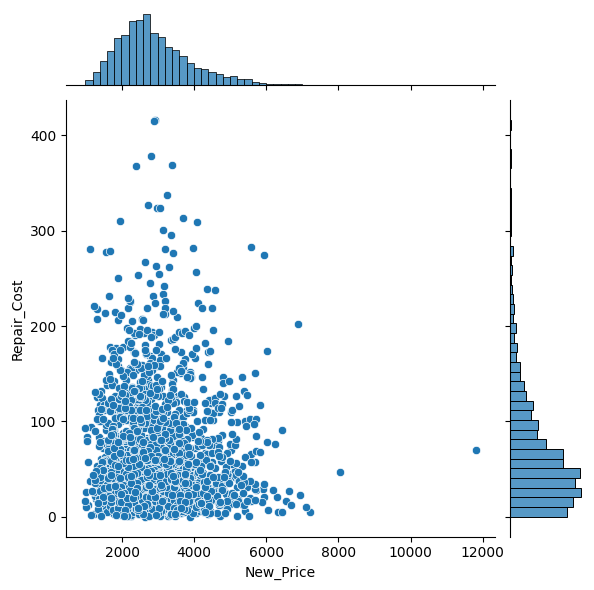

In [6]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.jointplot(data=data, x='New_Price', y='Repair_Cost', kind='scatter')
plt.show()


In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답04 = 'kind'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

두 변수의 관계와 각각의 분포를 한 그림에 그리는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.jointplot`. 정답은 4글자이고 첫 글자는 `k` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.jointplot(data=data, x='New_Price', y='Repair_Cost', ki__='scatter')
plt.show()

정답04 = 'ki__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 사고 이력 횟수(Accident_Cnt) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 다음 지침에 따라 이상치를 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- 사고 이력 횟수(Accident_Cnt)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (IQR 기준 K=2.0)
- AI모델링에 불필요한 등록번호(Reg_No) 컬럼을 삭제하세요
- 전처리를 적용한 데이터프레임은 data_temp 라는 변수명으로 보관하세요
- 아래 코드 셀의 빈칸 `< blank05_1 >`, `< blank05_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답05_1`, `정답05_2` 변수에 각각 저장하세요
    - 예시) 정답05_0 = 'data'
- 배점 : 6점

---

In [8]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

q1 = data['Accident_Cnt'].quantile(0.25)
q3 = data['Accident_Cnt'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

data_temp = data.drop( data[(data['Accident_Cnt'] > upper_fence) | (data['Accident_Cnt'] < lower_fence)].index, axis=0)
data_temp = data_temp.drop(columns=['Reg_No'])
data_temp.reset_index(drop=True, inplace=True)


In [ ]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답05_1 = 'index'
정답05_2 = 'reset_index'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 행 레이블(인덱스)을 가리키는 속성입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`. 정답은 5글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = data['Accident_Cnt'].quantile(0.25)
q3 = data['Accident_Cnt'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

data_temp = data.drop( data[(data['Accident_Cnt'] > upper_fence) | (data['Accident_Cnt'] < lower_fence)].ind__, axis=0)
data_temp = data_temp.drop(columns=['Reg_No'])
data_temp.reset______(drop=True, inplace=True)

정답05_1 = 'ind__'   # 빈칸 1에 넣은 단어
정답05_2 = 'reset______'   # 빈칸 2에 넣은 단어
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 아래 가이드에 따라 결측치를 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 대상 데이터프레임 : data_temp
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
- 전처리가 반영된 데이터프레임은 변수명 data_na 에 보관하세요
- 결측치가 사라졌는지 확인하세요
- 아래 코드 셀의 빈칸 `< blank06_1 >`, `< blank06_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답06_1`, `정답06_2` 변수에 각각 저장하세요
    - 예시) 정답06_0 = 'data'
- 배점 : 6점

---

In [9]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dropna()
print( '결측치 처리 후\n', data_na.isnull().sum() )


결측치 처리 전
 Quick_Sale        0
Mileage_Km        0
Engine_Cc         0
Car_Age           0
Accident_Cnt      0
Owner_Cnt        81
Inspect_Score     0
Option_Cnt        0
New_Price         0
Repair_Cost       0
Brand             0
Fuel              0
Gearbox           0
Color             0
dtype: int64
결측치 처리 후
 Quick_Sale       0
Mileage_Km       0
Engine_Cc        0
Car_Age          0
Accident_Cnt     0
Owner_Cnt        0
Inspect_Score    0
Option_Cnt       0
New_Price        0
Repair_Cost      0
Brand            0
Fuel             0
Gearbox          0
Color            0
dtype: int64


In [ ]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답06_1 = 'isnull'
정답06_2 = 'dropna'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 결측치가 있는 행을 삭제하는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`. 정답은 6글자이고 첫 글자는 `d` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
print( '결측치 처리 전\n', data_temp.isn___().sum() )
data_na = data_temp.dro___()
print( '결측치 처리 후\n', data_na.isnull().sum() )

정답06_1 = 'isn___'   # 빈칸 1에 넣은 단어
정답06_2 = 'dro___'   # 빈칸 2에 넣은 단어
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 변환하는 코드를 정정하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `data_na`
- 아래 가이드에 따라 인코딩하는데 오류가 발생하고 있습니다. 코드의 오류를 바로잡으세요
    - 대상 데이터프레임 : data_na
    - 문자열(범주형) 컬럼 Brand, Fuel, Gearbox, Color 을(를) get_dummies 로 인코딩하세요 (타깃 Quick_Sale 은 제외, drop_first=True)
    - 인코딩된 데이터프레임은 data_preset 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 data_preset 의 **전체 컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답07]** 의 값만 코드 셀 맨 아래에 `정답07 = 값` 형태로 입력하세요
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [13]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

data_preset = pd.get_dummies(data=data_na, columns=['Brand', 'Fuel', 'Gearbox', 'Color'], drop_first=True)
data_preset.info()

data_preset.shape[1]

<class 'pandas.core.frame.DataFrame'>
Index: 1761 entries, 0 to 1841
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Quick_Sale     1761 non-null   object 
 1   Mileage_Km     1761 non-null   int64  
 2   Engine_Cc      1761 non-null   int64  
 3   Car_Age        1761 non-null   float64
 4   Accident_Cnt   1761 non-null   int64  
 5   Owner_Cnt      1761 non-null   float64
 6   Inspect_Score  1761 non-null   int64  
 7   Option_Cnt     1761 non-null   int64  
 8   New_Price      1761 non-null   int64  
 9   Repair_Cost    1761 non-null   int64  
 10  Brand_국산B      1761 non-null   bool   
 11  Brand_수입A      1761 non-null   bool   
 12  Brand_수입B      1761 non-null   bool   
 13  Fuel_디젤        1761 non-null   bool   
 14  Fuel_전기        1761 non-null   bool   
 15  Fuel_하이브리드     1761 non-null   bool   
 16  Gearbox_자동     1761 non-null   bool   
 17  Color_기타       1761 non-null   bool   
 18  Color_은색     

21

In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답07 = '21'

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data_preset = pd.get_dummies(data=data_na, columns=['Brand', 'Fuel', 'Gearbox', 'Color'], drop_first=True)
data_preset.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_preset.shape[__]
```

</details>

### **8. 학습한 모델을 공정하게 평가하려면 학습에 쓰지 않은 검증 데이터가 필요합니다. 데이터를 훈련용과 검증용으로 나누려 합니다. 제시된 가이드에 맞춰 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 대상 데이터프레임 : data_preset
- 빠른 판매 여부(Quick_Sale) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- 결과를 재현할 수 있게 random_state 값을 2024 로 지정하세요
- 훈련과 검증 데이터셋 분리 — 훈련 : 검증 = 75:25 (train_size=0.75)
- 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [14]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.model_selection import train_test_split

X = data_preset.drop('Quick_Sale', axis=1)
y = data_preset['Quick_Sale']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.75, random_state=2024)
print(len(X_valid))

441


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
441

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = data_preset.drop('Quick_Sale', axis=1)
y = data_preset['Quick_Sale']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.75, random_state=2024)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 가이드에 따라 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 sc 변수에 할당하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 저장하세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 코드 셀 맨 아래에 `정답09 = 값` 형태로 입력하세요
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [17]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

round(np.min(X_valid), 2)


np.float64(-3.53)

In [ ]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답09 = '-3.53'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 빠른 판매 여부(Quick_Sale)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. DecisionTree와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(DecisionTreeClassifier, fit, RandomForestClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=8, min_samples_leaf=2
    - 난수 시드(random_state) : 42
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=150, max_depth=10
    - 난수 시드(random_state) : 42
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **잎(leaf) 노드 수** `dt.get_n_leaves()` 는 몇 개로 나타나나요?
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [18]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=2, random_state=42)
dt.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

dt.get_n_leaves()


np.int64(105)

In [ ]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답10 = '105'

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 결정나무 모델의 get_n_leaves() 메서드를 호출하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `DecisionTreeClassifier`, `fit`, `RandomForestClassifier`, `get_n_leaves`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=2, random_state=42)
dt.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

# [정답10] 실행한 결과를 입력하세요
dt.get_n_leaves()
```

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 RandomForest 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `rf`
- 아래 가이드에 따라 모델의 변수중요도를 파악하는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 RandomForest 모델 `rf` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 10 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[정답11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48652 (\N{HANGUL SYLLABLE BEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46300 (\N{HANGUL SYLLABLE DEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


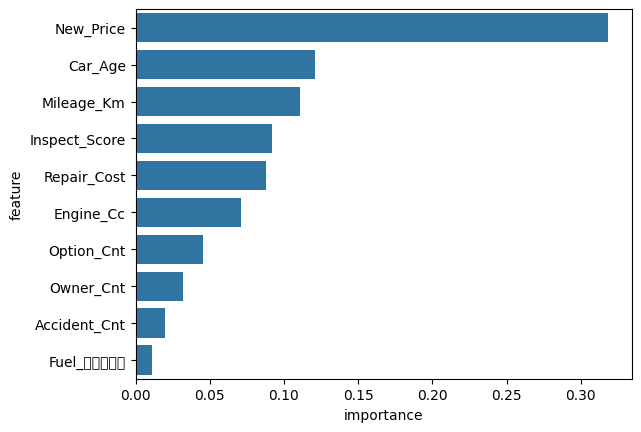

'New_Price'

In [20]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

fi['feature'].iloc[0]


In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답11 = 'New_Price'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `sort_values`, `iloc`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
fi['____'].iloc[__]
```

</details>

### **12. 앞서 학습시킨 DecisionTree와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, f1_score) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `rf`
- 제시된 가이드에 맞춰 각 모델의 F1-score(macro) 를 산출하려는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - 앞서 학습시킨 dt 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 F1-score(macro) 값을 각각 dt_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 F1-score(macro) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (DecisionTree / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [21]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import f1_score

y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

dt_score = f1_score(y_valid, y_pred_dt, average='macro')
rf_score = f1_score(y_valid, y_pred_rf, average='macro')
print(dt_score, rf_score)


0.7264015921669318 0.7433957872687071


In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답12 = 'RandomForest'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. F1-score(macro) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import f1_score

y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

dt_score = f1_score(y_valid, y_pred_dt, average='macro')
rf_score = f1_score(y_valid, y_pred_rf, average='macro')
print(dt_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(dt_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [22]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(100)

### **13. 빠른 판매 여부(Quick_Sale)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · scikit-learn(LabelEncoder, fit_transform, transform) · TensorFlow(Keras)(Sequential, EarlyStopping, ModelCheckpoint, compile) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - tensorflow framework 를 사용하세요
    - Dense 은닉층 2개를 노드 수 [16, 8] 순서로 쌓고, 활성화 함수는 'elu' 를 쓰세요
    - 비율 0.3 의 Dropout 층을 첫 번째 은닉층 뒤에 넣으세요
    - ModelCheckpoint('best_model.keras', save_best_only=True)를 callbacks 에 함께 넣으세요
    - 조기 종료 : EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True) 를 만들어 estop 에 저장하세요
    - 출력층은 노드 1개, activation='sigmoid' 로 하세요
    - optimizer 는 rmsprop, loss 는 binary_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
    - batch_size 는 32, epochs 는 200 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블)
    - 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

**[모델 구조도]**

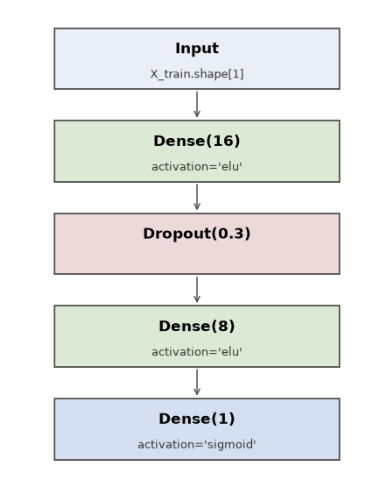

In [23]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

model = Sequential([
    Dense(16, activation='elu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(8, activation='elu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
cb_list = [estop]
ckpt = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
cb_list.append(ckpt)

model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=200, batch_size=32,
                    validation_data=(X_valid, y_valid_enc),
                    callbacks=cb_list)

print(model.count_params())

Epoch 1/200


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5962 - loss: 0.7364 - val_accuracy: 0.6372 - val_loss: 0.6296
Epoch 2/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6780 - loss: 0.5967 - val_accuracy: 0.7370 - val_loss: 0.5328
Epoch 3/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7106 - loss: 0.5699 - val_accuracy: 0.7596 - val_loss: 0.4847
Epoch 4/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7477 - loss: 0.5146 - val_accuracy: 0.7823 - val_loss: 0.4598
Epoch 5/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7652 - loss: 0.4876 - val_accuracy: 0.7959 - val_loss: 0.4438
Epoch 6/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7712 - loss: 0.4775 - val_accuracy: 0.8005 - val_loss: 0.4349
Epoch 7/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7780 - loss: 0.4705 - val_accuracy: 0.8027 - val_loss: 0.4303
Epoch 8/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7788 - loss: 0.4587 - val_accuracy: 0.8073 - val_loss: 0.

In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
481

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드를 위에서부터 코드로 옮기세요: 모델 구조 -> 콜백 -> compile -> fit.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

model = Sequential([
    Dense(16, activation='elu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(8, activation='elu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
cb_list = [estop]
ckpt = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
cb_list.append(ckpt)

model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=200, batch_size=32,
                    validation_data=(X_valid, y_valid_enc),
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 그래프 1개 안에 학습 Loss·검증 Loss 두 선을 모두 그리세요
- 범례를 'train', 'val' 로 표시하세요
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

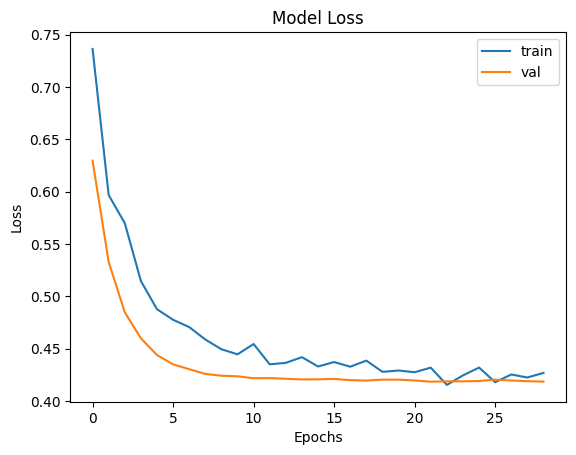

In [24]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답14_1 = 'ylabel'
정답14_2 = 'legend'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. y축 이름을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 6글자이고 첫 글자는 `y` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.yla___('Loss')
plt.leg___(['train', 'val'])
plt.show()

정답14_1 = 'yla___'   # 빈칸 1에 넣은 단어
정답14_2 = 'leg___'   # 빈칸 2에 넣은 단어
```

</details>